# Prerequisites. The mathematics behind the course, in code

Industrial AI, KBTU.

You took calculus, linear algebra and probability in your first two years. This notebook
brings back the part of them that the course really uses, and nothing else. Each idea gets a
formula, a sentence on what it means, and a few lines of NumPy, because from week 2 on the
mathematics reaches you as code: $\mathbf{X}^\top\mathbf{X}$ is `X.T @ X`, a gradient is an
array of the same shape as the weights.

Notation, the same in every notebook of the course: a bold lowercase letter is a vector
($\mathbf{x}$, $\mathbf{w}$), a bold capital is a matrix ($\mathbf{X}$, $\mathbf{C}$), a plain
letter is a number ($n$, $\lambda$).

| section | what | comes back in |
|---|---|---|
| 1 | the data matrix, products, norms, projections | every week |
| 2 | covariance, eigenvectors, SVD | week 2 (PCA), week 13 (PCA and SPE) |
| 3 | least squares, normal equations, ridge | week 9 (surrogate), week 11 (ridge), week 13 (ARX) |
| 4 | derivative, gradient, chain rule, gradient descent | week 7 (networks), week 11 (boosting) |
| 5 | constrained optimum, Lagrange multiplier, penalty | weeks 9 and 10 |
| 6 | distributions, quantiles, conditional probability, intervals | week 5 (threshold), week 11 (FMEA), week 13 (alarms) |
| 7 | self-check: five small functions with tests | |

Read it top to bottom; the outputs are already there. Run a cell again if you want to change a
number and see what moves. The self-check at the end is not graded. Its tests work the way the
tests of every practice do, so it is also a rehearsal of how you will hand in work.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

import scipy
from scipy import stats, optimize

BLUE, ORANGE, RED, GREEN, PURPLE, GREY = (
    "#2a6f8e", "#e07b39", "#c0392b", "#4a8f5a", "#9b3f9b", "#9aa0a6")

mpl.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#cccccc",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e6e6",
    "grid.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelsize": 10,
    "font.size": 10,
    "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"],
    "legend.frameon": False,
    "lines.linewidth": 1.6,
})

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

KAGGLE = {
    'ai4i': 'stephanmatzka/predictive-maintenance-dataset-ai4i-2020',
}


def dataset_folder(name):
    """The folder with the files of a data set: the Kaggle copy (downloaded once, then cached),
    or data/<name>/ of the course repo if Kaggle is out of reach."""
    if KAGGLE[name]:
        try:
            import contextlib, io, logging, kagglehub
            logging.getLogger("kagglehub").setLevel(logging.ERROR)
            with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
                folder = Path(kagglehub.dataset_download(KAGGLE[name]))
            print(f"{name}: Kaggle {KAGGLE[name]}")
            return folder
        except Exception as exc:
            print(f"Kaggle unavailable ({type(exc).__name__}), looking for data/{name}/")
    for root in [Path.cwd(), *Path.cwd().parents]:
        if (root / "data" / name).is_dir():
            return root / "data" / name
    raise FileNotFoundError(f"no data/{name}/ here or above; run data/fetch.py in the course repo")

print(" | ".join(f"{m} {sys.modules[m].__version__}" for m in
                 ("numpy", "pandas", "matplotlib", "scipy", "sklearn", "torch") if m in sys.modules))

numpy 2.5.5 | pandas 3.1.1 | matplotlib 3.11.2 | scipy 1.18.1 | torch 2.8.0+cu128


---

# 1. Vectors and matrices

## 1.1 The data matrix

Almost every data set in the course becomes one matrix $\mathbf{X}$ of size $n \times d$: a row
per observation (a machining cycle, a second of a pump log), a column per quantity (a sensor).
Row $i$ is the vector $\mathbf{x}_i \in \mathbb{R}^d$, one moment of the plant.

Here are five sensors of the AI4I milling machine that In-class work 1 opens with.

In [3]:
df = pd.read_csv(dataset_folder("ai4i") / "ai4i2020.csv", encoding="utf-8-sig")
SENSORS = ["Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]",
           "Torque [Nm]", "Tool wear [min]"]
X = df[SENSORS].to_numpy()
y_fail = df["Machine failure"].to_numpy()

n, d = X.shape
print(f"X is {n} x {d}")
print("row 0, one cycle:   ", X[0])
print("column 3, torque:   ", X[:5, 3], "...")

ai4i: Kaggle stephanmatzka/predictive-maintenance-dataset-ai4i-2020
X is 10000 x 5
row 0, one cycle:    [ 298.1  308.6 1551.    42.8    0. ]
column 3, torque:    [42.8 46.3 49.4 39.5 40. ] ...


`axis=0` runs down the rows, so `X.mean(axis=0)` is one mean per sensor, a vector of length
$d$. Subtracting it from $\mathbf{X}$ works by **broadcasting**: NumPy repeats the vector for
every row. Half of the shape bugs in the course are an axis mixed up here.

In [4]:
mu = X.mean(axis=0)                 # (5,)
Xc = X - mu                         # (10000, 5) - (5,)  ->  (10000, 5)
print("means:", mu.round(2))
print("centred means:", Xc.mean(axis=0).round(12))
print("mean over the wrong axis has shape", X.mean(axis=1).shape)

means: [ 300.    310.01 1538.78   39.99  107.95]
centred means: [-0.  0. -0.  0.  0.]
mean over the wrong axis has shape (10000,)


## 1.2 The product $\mathbf{X}\mathbf{w}$ is a linear model

A linear model gives every row a score $\hat y_i = \mathbf{x}_i^\top \mathbf{w}$, the sum
$\sum_j x_{ij} w_j$. Written for all rows at once it is one matrix product,
$\hat{\mathbf{y}} = \mathbf{X}\mathbf{w}$, with shapes $(n \times d)(d) \to (n)$. The inner
dimensions must agree, and checking them is the fastest way to find a bug in a formula.

In [5]:
w = np.array([0.0, 0.0, 0.0, 0.1, 0.01])       # some weights, one per sensor
scores = X @ w
print(X.shape, "@", w.shape, "->", scores.shape)
print("first scores:", scores[:3].round(3))
print("same as a loop:", round(sum(X[0, j] * w[j] for j in range(d)), 3))

(10000, 5) @ (5,) -> (10000,)
first scores: [4.28 4.66 4.99]
same as a loop: 4.28


## 1.3 Dot product, norm, projection

The dot product $\mathbf{a}^\top\mathbf{b} = \|\mathbf{a}\|\,\|\mathbf{b}\|\cos\theta$ measures
how much two vectors point the same way. The norm $\|\mathbf{a}\| = \sqrt{\mathbf{a}^\top\mathbf{a}}$
is the length.

When $\mathbf{u}$ has length 1, the number $\mathbf{a}^\top\mathbf{u}$ is the length of the
shadow of $\mathbf{a}$ on the line of $\mathbf{u}$, and the shadow itself is
$(\mathbf{a}^\top\mathbf{u})\,\mathbf{u}$. What is left over,
$\mathbf{a} - (\mathbf{a}^\top\mathbf{u})\mathbf{u}$, is perpendicular to $\mathbf{u}$. Two
methods of the course are this picture: PCA projects the data on a few chosen directions,
least squares projects $\mathbf{y}$ on the columns of $\mathbf{X}$.

|u| = 0.9999999999999999   a.u = 2.828
shadow: [2. 2.]   rest: [ 1. -1.]   rest.u = 0.0


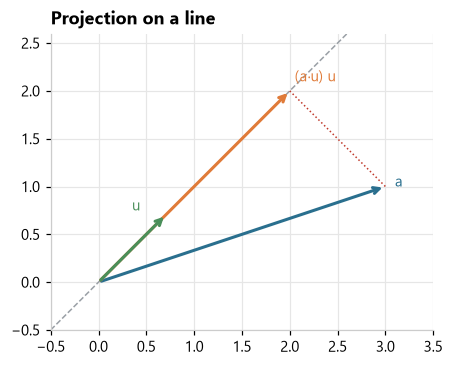

In [6]:
a = np.array([3.0, 1.0])
u = np.array([1.0, 1.0]) / np.sqrt(2)          # unit vector
shadow = (a @ u) * u
rest = a - shadow

print("|u| =", np.linalg.norm(u), "  a.u =", round(a @ u, 3))
print("shadow:", shadow, "  rest:", rest, "  rest.u =", round(rest @ u, 12))

# each arrow: the vector, its colour, its label and where the label goes
arrows = [
    (a, BLUE, "a", (3.1, 1.0)),
    (shadow, ORANGE, "(a·u) u", (2.05, 2.1)),
    (u, GREEN, "u", (0.35, 0.75)),
]

fig, ax = plt.subplots(figsize=(4.5, 3.5))
ax.axline((0, 0), u, color=GREY, lw=1, ls="--")
for vector, colour, label, label_at in arrows:
    arrow_style = dict(arrowstyle="->", color=colour, lw=2)
    ax.annotate("", vector, (0, 0), arrowprops=arrow_style)
    ax.text(*label_at, label, color=colour)
ax.plot(*zip(shadow, a), color=RED, lw=1, ls=":")
ax.set(xlim=(-0.5, 3.5), ylim=(-0.5, 2.6), aspect="equal", title="Projection on a line")
plt.show()

---

# 2. Covariance and eigenvectors

## 2.1 Standardising

Sensors come in different units: kelvin, rpm, minutes. Before we compare them we standardise
each column, $z_{ij} = (x_{ij} - \mu_j)/\sigma_j$. Every column then has mean 0 and standard
deviation 1, and a value of $z = 2$ means "two standard deviations above usual" for any sensor.

`np.std` divides by $n$, `pandas.std` by $n - 1$. On 10 000 rows it does not matter; on 10 it
does, so say which one you use.

In [7]:
Z = (X - X.mean(axis=0)) / X.std(axis=0)
print("means:", Z.mean(axis=0).round(12))
print("stds: ", Z.std(axis=0).round(12))

means: [-0.  0. -0.  0.  0.]
stds:  [1. 1. 1. 1. 1.]


## 2.2 The covariance matrix

For centred data $\mathbf{X}_c$, the covariance matrix is

$$\mathbf{C} = \frac{1}{n-1}\,\mathbf{X}_c^\top \mathbf{X}_c, \qquad C_{jk} = \frac{1}{n-1}\sum_i (x_{ij}-\mu_j)(x_{ik}-\mu_k).$$

It is $d \times d$, symmetric, and on the diagonal stand the variances. For standardised data
it is the correlation matrix: $C_{jk}$ is the correlation of sensors $j$ and $k$. One matrix
product gives all $d^2$ pairs at once.

In [8]:
C = Z.T @ Z / (n - 1)
names = ["air", "process", "rpm", "torque", "wear"]
print(pd.DataFrame(C, index=names, columns=names).round(2))
print("\nsame as np.corrcoef:", np.allclose(C, np.corrcoef(X, rowvar=False), atol=1e-3))

           air  process    rpm  torque   wear
air      1.000    0.880  0.020  -0.010  0.010
process  0.880    1.000  0.020  -0.010  0.010
rpm      0.020    0.020  1.000  -0.880  0.000
torque  -0.010   -0.010 -0.880   1.000 -0.000
wear     0.010    0.010  0.000  -0.000  1.000

same as np.corrcoef: True


Two strong pairs: the two temperatures (they move together) and speed with torque (the motor
holds roughly constant power, so when one goes up the other goes down).

## 2.3 Eigenvectors: the directions in which the data spread

Take a unit vector $\mathbf{v}$ and project every row on it: the scores are
$\mathbf{Z}\mathbf{v}$. Their variance is

$$\operatorname{Var}(\mathbf{Z}\mathbf{v}) = \frac{1}{n-1}\mathbf{v}^\top \mathbf{Z}^\top\mathbf{Z}\,\mathbf{v} = \mathbf{v}^\top\mathbf{C}\,\mathbf{v}.$$

Which direction gives the largest variance? Maximising $\mathbf{v}^\top\mathbf{C}\mathbf{v}$
under $\|\mathbf{v}\| = 1$ leads (with the Lagrange multiplier of section 5) to
$\mathbf{C}\mathbf{v} = \lambda\mathbf{v}$. So the best direction is an **eigenvector** of
$\mathbf{C}$, and the variance along it is its **eigenvalue** $\lambda$. The eigenvectors of a
symmetric matrix are perpendicular to each other, and the eigenvalues add up to the total
variance $\operatorname{tr}\mathbf{C}$. That is all of PCA: rotate the axes to the
eigenvectors and keep the ones with large $\lambda$.

Two temperatures with correlation $r$ give the cleanest case. Their correlation matrix is
$\begin{pmatrix}1 & r\\ r & 1\end{pmatrix}$, its eigenvectors are $(1,1)/\sqrt2$ and
$(1,-1)/\sqrt2$, its eigenvalues $1+r$ and $1-r$.

r = 0.876   eigenvalues [1.876 0.124]   1+r, 1-r = 1.876, 0.124
eigenvectors (columns):
 [[ 0.707  0.707]
 [ 0.707 -0.707]]
variance of the projections: [1.876 0.124]


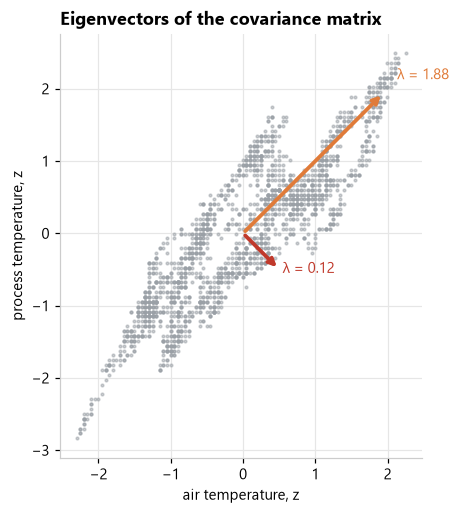

In [9]:
Z2 = Z[:, :2]                                   # air and process temperature
C2 = Z2.T @ Z2 / (n - 1)
# eigh is for symmetric matrices and returns the eigenvalues in ascending order
lam, V = np.linalg.eigh(C2)
lam = lam[::-1]
V = V[:, ::-1]
# the sign of an eigenvector is arbitrary: make its first entry positive
V = V * np.sign(V[0])

r = C2[0, 1]
print(f"r = {r:.3f}   eigenvalues {lam.round(3)}   1+r, 1-r = {1 + r:.3f}, {1 - r:.3f}")
print("eigenvectors (columns):\n", V.round(3))
projection_var = (Z2 @ V).var(axis=0, ddof=1)
print("variance of the projections:", projection_var.round(3))

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(*Z2[::5].T, s=3, color=GREY, alpha=0.5)
for k, colour in [(0, ORANGE), (1, RED)]:
    end = V[:, k] * 2 * np.sqrt(lam[k])
    arrow_style = dict(arrowstyle="->", color=colour, lw=2.5)
    ax.annotate("", end, (0, 0), arrowprops=arrow_style)
    ax.text(*(end * 1.1), f"λ = {lam[k]:.2f}", color=colour)
ax.set(xlabel="air temperature, z", ylabel="process temperature, z", aspect="equal",
       title="Eigenvectors of the covariance matrix")
plt.show()

Nearly all the variance of the two sensors lies along the diagonal, the direction "both
temperatures up". Along the other eigenvector, the difference of the two, there is little
left. Keeping only the first component would lose little, and that is how PCA compresses.
The small direction is just as useful: a point far out along it breaks the usual relation of
the sensors, which is how week 13 detects faults.

## 2.4 SVD gives the same thing without forming $\mathbf{C}$

Any matrix factors as $\mathbf{Z} = \mathbf{U}\mathbf{S}\mathbf{V}^\top$ with orthonormal
columns in $\mathbf{U}$ and $\mathbf{V}$ and non-negative singular values $s_k$ on the diagonal
of $\mathbf{S}$. Put it into $\mathbf{C}$:

$$\mathbf{C} = \frac{1}{n-1}\mathbf{V}\mathbf{S}\mathbf{U}^\top\mathbf{U}\mathbf{S}\mathbf{V}^\top = \mathbf{V}\,\frac{\mathbf{S}^2}{n-1}\,\mathbf{V}^\top .$$

So the columns of $\mathbf{V}$ are the eigenvectors and $\lambda_k = s_k^2/(n-1)$. Libraries
(scikit-learn's `PCA` among them) use the SVD because it is more accurate than forming
$\mathbf{Z}^\top\mathbf{Z}$ first.

In [10]:
U, s, Vt = np.linalg.svd(Z, full_matrices=False)
lam_svd = s**2 / (n - 1)
lam_eig = np.linalg.eigvalsh(C)[::-1]
print("from SVD:  ", lam_svd.round(4))
print("from eigh: ", lam_eig.round(4))
print("share of variance:", (lam_svd / lam_svd.sum()).round(3))

from SVD:   [1.9109 1.841  0.9997 0.1263 0.1225]
from eigh:  [1.9109 1.841  0.9997 0.1263 0.1225]
share of variance: [0.382 0.368 0.2   0.025 0.025]


Five sensors, but the last two eigenvalues are small. Each of the two correlated pairs of
section 2.2 leaves one direction, the difference of the pair, almost empty, so three components
carry 95 % of the variance.

---

# 3. Least squares

## 3.1 The normal equations

We want weights $\mathbf{w}$ with $\mathbf{X}\mathbf{w} \approx \mathbf{y}$, and measure the
miss by the sum of squared residuals

$$L(\mathbf{w}) = \|\mathbf{y} - \mathbf{X}\mathbf{w}\|^2 .$$

The gradient is $\nabla L = -2\mathbf{X}^\top(\mathbf{y} - \mathbf{X}\mathbf{w})$. Setting it to
zero gives the **normal equations**

$$\mathbf{X}^\top\mathbf{X}\,\mathbf{w} = \mathbf{X}^\top\mathbf{y}.$$

The picture behind them is section 1.3. The vector $\mathbf{X}\mathbf{w}$ can only lie in the
space spanned by the columns of $\mathbf{X}$. The closest such point to $\mathbf{y}$ is its
projection, and there the residual $\mathbf{r} = \mathbf{y} - \mathbf{X}\mathbf{w}$ is
perpendicular to every column: $\mathbf{X}^\top\mathbf{r} = \mathbf{0}$, which is the same
equation.

An intercept is a column of ones in $\mathbf{X}$. Below, a simulated furnace: the temperature
rise depends on fuel flow and air flow, and we know the true weights.

In [11]:
rng = np.random.default_rng(0)
m = 200
fuel = rng.uniform(1, 5, m)                     # kg/h
air = rng.uniform(10, 30, m)                    # m3/h
rise = 5 + 30 * fuel - 1.5 * air + rng.normal(0, 3, m)    # K

A = np.column_stack([np.ones(m), fuel, air])
w_hat = np.linalg.solve(A.T @ A, A.T @ rise)
resid = rise - A @ w_hat

print("true      [5, 30, -1.5]")
print("estimated", w_hat.round(2))
print("X^T r =", (A.T @ resid).round(9), "  (perpendicular)")
print("same as lstsq:", np.allclose(w_hat, np.linalg.lstsq(A, rise, rcond=None)[0]))

true      [5, 30, -1.5]
estimated [ 4.52 29.97 -1.47]
X^T r = [ 0. -0. -0.]   (perpendicular)
same as lstsq: True


Use `np.linalg.solve`, never `np.linalg.inv(A.T @ A) @ ...`: solving is cheaper and loses less
accuracy than inverting.

## 3.2 When $\mathbf{X}^\top\mathbf{X}$ is nearly singular: ridge

Plants often have two sensors that measure almost the same thing: a duplicate thermocouple, a
flow and the valve position that sets it. Then the columns of $\mathbf{X}$ are nearly parallel,
$\mathbf{X}^\top\mathbf{X}$ is nearly singular, and the data cannot tell the two weights apart.
Least squares answers with two huge weights of opposite sign that cancel.

Ridge regression adds a penalty $\lambda\|\mathbf{w}\|^2$ to the loss. The normal equations
become

$$(\mathbf{X}^\top\mathbf{X} + \lambda\mathbf{I})\,\mathbf{w} = \mathbf{X}^\top\mathbf{y}.$$

Adding $\lambda$ to the diagonal adds $\lambda$ to every eigenvalue of $\mathbf{X}^\top\mathbf{X}$,
so the tiny eigenvalue that made the system unstable is gone. The **condition number**, the
ratio of the largest eigenvalue to the smallest, says how much the solution amplifies noise.

In [12]:
rng = np.random.default_rng(1)
t1 = rng.normal(0, 1, 100)                       # thermocouple 1, standardised
t2 = t1 + rng.normal(0, 0.005, 100)              # thermocouple 2, nearly the same
B = np.column_stack([t1, t2])

for lam_r in [0.0, 0.1, 1.0, 10.0]:
    M = B.T @ B + lam_r * np.eye(2)

    # five batches of the same process, differing only in the noise of the target
    fits = []
    for _ in range(5):
        target = t1 + rng.normal(0, 0.3, 100)
        fits.append(np.linalg.solve(M, B.T @ target))

    weights_text = "  ".join(f"[{w1:6.2f} {w2:6.2f}]" for w1, w2 in fits)
    print(f"lambda = {lam_r:4.1f}   condition number {np.linalg.cond(M):8.0f}   "
          f"weights of five batches: {weights_text}")

lambda =  0.0   condition number   118141   weights of five batches: [  1.10  -0.10]  [ -3.88   4.93]  [ -0.73   1.72]  [-11.13  12.07]  [  1.63  -0.68]
lambda =  0.1   condition number     1444   weights of five batches: [  0.57   0.48]  [  0.41   0.60]  [  0.45   0.53]  [  0.53   0.50]  [  0.63   0.39]
lambda =  1.0   condition number      147   weights of five batches: [  0.51   0.51]  [  0.48   0.47]  [  0.50   0.51]  [  0.51   0.51]  [  0.50   0.49]
lambda = 10.0   condition number       16   weights of five batches: [  0.47   0.47]  [  0.47   0.47]  [  0.48   0.48]  [  0.49   0.49]  [  0.46   0.46]


Without the penalty the weights jump from batch to batch, often to large values of opposite
sign; only their sum stays near 1. The data simply cannot say how to split the signal between
two copies of one sensor. With a small $\lambda$ both weights settle near 0.5, which is what a
person would say: the target follows the temperature, and both sensors read it. Too large a
$\lambda$ starts to shrink the sum below 1, so $\lambda$ is chosen on validation data.

---

# 4. Derivatives and gradients

## 4.1 A derivative you can check

The central difference

$$f'(x) \approx \frac{f(x+h) - f(x-h)}{2h}$$

has an error of order $h^2$. For a function of many variables, do it once per coordinate and
you get the gradient $\nabla f$, the vector of partial derivatives. It points where $f$ grows
fastest. Numerical gradients are too slow to train with, but they are the standard way to test
a gradient written by hand.

Too small an $h$ is as bad as too large: $f(x+h) - f(x-h)$ then subtracts two nearly equal
numbers and rounding error, about $10^{-16}/h$, takes over.

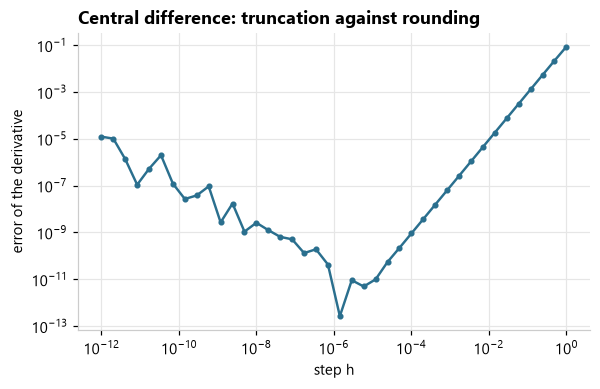

best h here: 1e-06, error 2.6e-13


In [13]:
f = np.sin
x0 = 1.0
hs = np.logspace(-12, 0, 40)
err = np.abs((f(x0 + hs) - f(x0 - hs)) / (2 * hs) - np.cos(x0))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.loglog(hs, err, color=BLUE, marker=".")
ax.set(xlabel="step h", ylabel="error of the derivative",
       title="Central difference: truncation against rounding")
plt.show()
print(f"best h here: {hs[err.argmin()]:.0e}, error {err.min():.1e}")

## 4.2 Gradient descent, and why the step size has a limit

Gradient descent repeats $\mathbf{w} \leftarrow \mathbf{w} - \eta\,\nabla L(\mathbf{w})$. On the
mean squared error $L = \frac1n\|\mathbf{y} - \mathbf{X}\mathbf{w}\|^2$ of section 3, the
gradient is $-\frac2n\mathbf{X}^\top(\mathbf{y}-\mathbf{X}\mathbf{w})$ and the second derivative
(the Hessian) is the constant matrix $\mathbf{H} = \frac2n\mathbf{X}^\top\mathbf{X}$.

Along each eigenvector of $\mathbf{H}$ the error is multiplied by $1 - \eta\lambda_k$ at every
step. If $|1 - \eta\lambda_k| > 1$ for any $k$, it grows instead of shrinking. So the step must
satisfy

$$\eta < \frac{2}{\lambda_{\max}(\mathbf{H})}.$$

This is why features are standardised before training: on raw columns $\lambda_{\max}$ is huge,
the allowed step tiny, and the directions with small $\lambda$ crawl.

eta must stay below 0.952


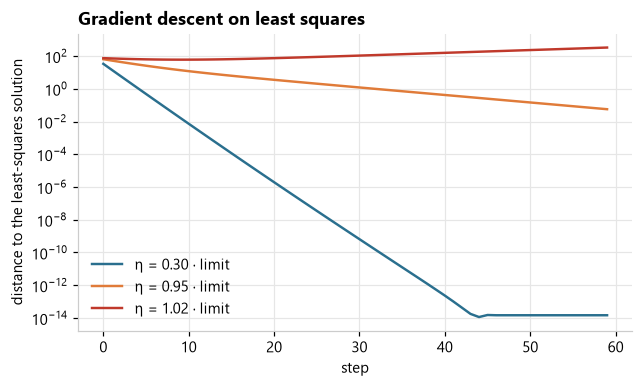

In [14]:
fuel_z = (fuel - fuel.mean()) / fuel.std()
air_z = (air - air.mean()) / air.std()
Af = np.column_stack([np.ones(m), fuel_z, air_z])
H = 2 / m * Af.T @ Af
eta_max = 2 / np.linalg.eigvalsh(H).max()
w_best = np.linalg.solve(Af.T @ Af, Af.T @ rise)
print(f"eta must stay below {eta_max:.3f}")

fig, ax = plt.subplots(figsize=(6.5, 3.5))
for share, colour in [(0.3, BLUE), (0.95, ORANGE), (1.02, RED)]:
    eta = share * eta_max
    wg = np.zeros(3)
    dist = []
    for _ in range(60):
        residual = rise - Af @ wg
        wg = wg + eta * 2 / m * Af.T @ residual       # w - eta * gradient
        dist.append(np.linalg.norm(wg - w_best))
    ax.semilogy(dist, color=colour, label=f"η = {share:.2f} · limit")
ax.set(xlabel="step", ylabel="distance to the least-squares solution",
       title="Gradient descent on least squares")
ax.legend()
plt.show()

## 4.3 The chain rule is backpropagation

A network is a chain of simple functions, and its gradient is the chain rule applied from the
end backwards. Take the smallest network of week 7: two inputs, two ReLU units, one sigmoid
output, binary cross-entropy loss.

$$\mathbf{z}_1 = \mathbf{W}_1\mathbf{x} + \mathbf{b}_1,\quad \mathbf{h} = \max(\mathbf{0}, \mathbf{z}_1),\quad z_2 = \mathbf{w}_2^\top\mathbf{h} + b_2,\quad p = \sigma(z_2),\quad L = -\big[y\log p + (1-y)\log(1-p)\big].$$

Going backwards, each line multiplies by the derivative of one step:

| quantity | gradient |
|---|---|
| $z_2$ | $\partial L/\partial z_2 = p - y$ (sigmoid and cross-entropy simplify to this) |
| $\mathbf{w}_2$, $b_2$ | $(p - y)\,\mathbf{h}$ and $p - y$ |
| $\mathbf{h}$ | $(p - y)\,\mathbf{w}_2$ |
| $\mathbf{z}_1$ | the same, times $1$ where $\mathbf{z}_1 > 0$ and $0$ elsewhere |
| $\mathbf{W}_1$, $\mathbf{b}_1$ | $\boldsymbol{\delta}_1\mathbf{x}^\top$ and $\boldsymbol{\delta}_1$, with $\boldsymbol{\delta}_1 = \partial L/\partial\mathbf{z}_1$ |

The ReLU acts as a gate: a unit that was off in the forward pass passes no gradient back. The
numbers below are chosen so that one unit is off. PyTorch's `backward()` does exactly this
table, and we check it against our hand calculation.

In [15]:
import torch

x_in = np.array([1.0, 2.0])
y_lab = 1.0
W1 = np.array([[0.5, -1.0], [1.0, 0.5]])
b1 = np.zeros(2)
w2 = np.array([1.0, -0.5])
b2 = 0.5

# forward
z1 = W1 @ x_in + b1
h = np.maximum(0, z1)
z2 = w2 @ h + b2
p = 1 / (1 + np.exp(-z2))
L = -(y_lab * np.log(p) + (1 - y_lab) * np.log(1 - p))
print("z1 =", z1, " h =", h, f" p = {p:.4f}  L = {L:.4f}")

# backward, by hand
d_z2 = p - y_lab
d_w2 = d_z2 * h
d_b2 = d_z2
d_z1 = np.where(z1 > 0, d_z2 * w2, 0.0)        # the ReLU gate
d_W1 = np.outer(d_z1, x_in)
d_b1 = d_z1


# the same with autograd
def leaf(a):
    return torch.tensor(a, dtype=torch.float64, requires_grad=True)


tW1, tb1, tw2, tb2 = leaf(W1), leaf(b1), leaf(w2), leaf(b2)
th = torch.relu(tW1 @ torch.tensor(x_in) + tb1)
tp = torch.sigmoid(tw2 @ th + tb2)
tL = -(y_lab * torch.log(tp) + (1 - y_lab) * torch.log(1 - tp))
tL.backward()

print("dL/dW1 by hand:\n", d_W1.round(4))
print("dL/dW1 by torch:\n", tW1.grad.numpy().round(4))
pairs = [(d_W1, tW1), (d_b1, tb1), (d_w2, tw2), (d_b2, tb2)]
agree = all(np.allclose(by_hand, t.grad.numpy()) for by_hand, t in pairs)
print("all four agree:", agree)

z1 = [-1.5  2. ]  h = [0. 2.]  p = 0.3775  L = 0.9741
dL/dW1 by hand:
 [[0.     0.    ]
 [0.3112 0.6225]]
dL/dW1 by torch:
 [[0.     0.    ]
 [0.3112 0.6225]]
all four agree: True


---

# 5. Optimisation with a constraint

## 5.1 The Lagrange multiplier

In week 9 we look for the cheapest setpoint of a dryer that still keeps the product dry enough:
minimise a cost $f(\mathbf{x})$ subject to a limit $g(\mathbf{x}) \le 0$. A small example with a
picture: minimise

$$f(x, y) = (x-2)^2 + (y-1)^2 \quad\text{subject to}\quad g(x, y) = x + y - 1 \le 0.$$

Without the constraint the minimum is $(2, 1)$, where $g = 2 > 0$: forbidden. So the answer lies
on the boundary $x + y = 1$. Walk along the boundary and watch the level lines of $f$: at the
best point a level line just touches the boundary. Touching means the two gradients are
parallel,

$$\nabla f = -\lambda\,\nabla g, \qquad \lambda \ge 0 .$$

Here $\nabla f = (2(x-2), 2(y-1))$ and $\nabla g = (1, 1)$, so $x - 2 = y - 1$, and with
$x + y = 1$ that gives $(x, y) = (1, 0)$ and $\lambda = 2$.

The multiplier has a meaning you can use: it is the price of the constraint. Relax the limit to
$g \le \varepsilon$ and the optimal cost falls by about $\lambda\varepsilon$.

## 5.2 KKT in one line

For an inequality the conditions (Karush–Kuhn–Tucker) add one rule: either the constraint is
active ($g = 0$, $\lambda \ge 0$) or it is slack ($g < 0$, $\lambda = 0$). In short,
$\lambda\,g(\mathbf{x}) = 0$. If the free minimum already satisfies the limit, the limit costs
nothing.

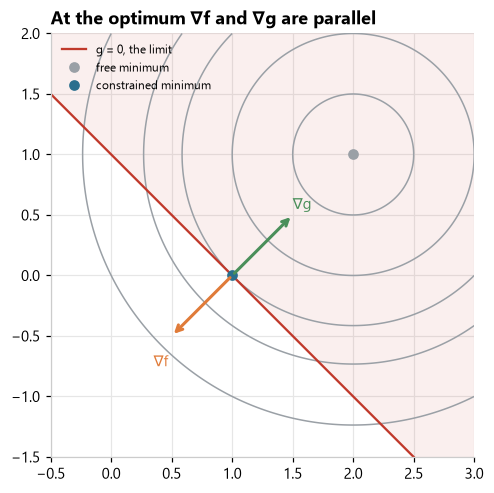

grad f at the optimum: [-2. -2.]  = -2 * grad g, so lambda = 2


In [16]:
fobj = lambda v: (v[0] - 2) ** 2 + (v[1] - 1) ** 2
gcon = lambda v: v[0] + v[1] - 1
x_opt = np.array([1.0, 0.0])

gx, gy = np.meshgrid(np.linspace(-0.5, 3, 200), np.linspace(-1.5, 2, 200))
fig, ax = plt.subplots(figsize=(5, 5))
ax.contour(gx, gy, fobj([gx, gy]), levels=[0.25, 1, 2, 3, 5], colors=GREY, linewidths=1)
ax.contourf(gx, gy, gcon([gx, gy]), levels=[0, 10], colors=[RED], alpha=0.08)
ax.axline((0, 1), (1, 0), color=RED, lw=1.5, label="g = 0, the limit")
ax.plot(2, 1, "o", color=GREY, label="free minimum")
ax.plot(*x_opt, "o", color=BLUE, label="constrained minimum")
grad_f = np.array([2 * (x_opt[0] - 2), 2 * (x_opt[1] - 1)])
grad_g = np.array([1, 1])
ax.annotate("", x_opt + 0.25 * grad_f, x_opt,
            arrowprops=dict(arrowstyle="->", color=ORANGE, lw=2))
ax.annotate("", x_opt + 0.5 * grad_g, x_opt,
            arrowprops=dict(arrowstyle="->", color=GREEN, lw=2))
ax.text(0.35, -0.75, "∇f", color=ORANGE)
ax.text(1.5, 0.55, "∇g", color=GREEN)
ax.set(aspect="equal", title="At the optimum ∇f and ∇g are parallel")
ax.legend(loc="upper left", fontsize=8)
plt.show()
print("grad f at the optimum:", grad_f, " = -2 * grad g, so lambda = 2")

## 5.3 A penalty instead of a constraint

Many optimisers of the course (Nelder–Mead, a genetic algorithm, particle swarm) know nothing of
constraints. The usual trick is to add the violation to the cost:

$$F_w(\mathbf{x}) = f(\mathbf{x}) + w\,\max(0,\ g(\mathbf{x})).$$

How large must $w$ be? Step from the boundary into the forbidden side by $\varepsilon$: $f$ falls
by about $\lambda\varepsilon$, the penalty rises by $w\varepsilon$. The step pays off while
$w < \lambda$. So with $w > \lambda$ the minimum of $F_w$ is exactly the constrained minimum,
and with $w < \lambda$ it is not. The squared penalty $w\max(0, g)^2$ is smooth, but for any
finite $w$ it leaves the solution slightly on the wrong side.

In [17]:
start = [2.0, 1.0]
tolerances = {"xatol": 1e-9, "fatol": 1e-12}

rows = []
for wpen in [0.5, 1.0, 1.9, 2.1, 5.0, 50.0]:
    linear = lambda v: fobj(v) + wpen * max(0.0, gcon(v))
    squared = lambda v: fobj(v) + wpen * max(0.0, gcon(v)) ** 2
    lin = optimize.minimize(linear, start, method="Nelder-Mead", options=tolerances)
    sq = optimize.minimize(squared, start, method="Nelder-Mead", options=tolerances)
    rows.append({"w": wpen,
                 "linear penalty: g at the answer": gcon(lin.x),
                 "squared penalty: g at the answer": gcon(sq.x)})

table = pd.DataFrame(rows)
print(table.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

      w  linear penalty: g at the answer  squared penalty: g at the answer
 0.5000                           1.5000                            1.0000
 1.0000                           1.0000                            0.6667
 1.9000                           0.1000                            0.4167
 2.1000                          -0.0000                            0.3846
 5.0000                           0.0000                            0.1818
50.0000                           0.0000                            0.0198


The linear penalty is exact from $w = 2.1$ on, just above $\lambda = 2$; below that it lands on
the forbidden side. The squared penalty crosses the limit by about $\lambda/(2w)$ and gets there
only as $w \to \infty$. Week 9 meets the same rule with $\lambda$ read off a real optimiser.

---

# 6. Probability and estimates

## 6.1 The normal distribution and its quantiles

If a healthy sensor reading is normal with mean $\mu$ and standard deviation $\sigma$, then
$z = (x - \mu)/\sigma$ is standard normal, and the share of readings above $\mu + z\sigma$ is
$1 - \Phi(z)$. The **quantile** goes the other way: $z_{0.99} = \Phi^{-1}(0.99) = 2.33$ is the
point that 99 % of readings stay below. An alarm limit at $\mu + 2.33\sigma$ therefore raises a
false alarm on 1 % of healthy readings. This share is the false alarm rate, FAR.

The catch: the formula is only as good as the normal assumption. Residuals of real processes
often have heavier tails. The empirical quantile of healthy data, `np.quantile(x, 0.99)`,
assumes nothing, and it is what week 13 uses.

In [18]:
rng = np.random.default_rng(2)
z_99 = stats.norm.ppf(0.99)
beyond_3_sigma = 2 * stats.norm.sf(3)
print("z_0.99 =", round(z_99, 3), "   share beyond 3 sigma:", round(beyond_3_sigma, 4))

laws = [("normal", lambda k: rng.normal(0, 1, k)),
        ("heavy tails (t, 3 dof)", lambda k: rng.standard_t(3, k))]
for name, draw in laws:
    healthy = draw(20_000)          # data the limit is set on
    fresh = draw(500_000)           # new healthy data the limit is judged on
    for target_far in [0.01, 0.001]:
        z = stats.norm.ppf(1 - target_far)
        by_formula = healthy.mean() + z * healthy.std()
        by_quantile = np.quantile(healthy, 1 - target_far)
        far_formula = np.mean(fresh > by_formula)
        far_quantile = np.mean(fresh > by_quantile)
        print(f"{name:24} target FAR {target_far:.1%}:  formula gives {far_formula:.2%}, "
              f"empirical quantile {far_quantile:.2%}")

z_0.99 = 2.326    share beyond 3 sigma: 0.0027
normal                   target FAR 1.0%:  formula gives 0.97%, empirical quantile 0.96%
normal                   target FAR 0.1%:  formula gives 0.10%, empirical quantile 0.12%
heavy tails (t, 3 dof)   target FAR 1.0%:  formula gives 1.35%, empirical quantile 0.97%
heavy tails (t, 3 dof)   target FAR 0.1%:  formula gives 0.63%, empirical quantile 0.11%


On normal data both ways hit the target. On heavy tails the formula misses, and the further out
the limit, the worse: at a target of 0.1 % it gives about six times as many false alarms. The
empirical quantile stays on target in both cases.

## 6.2 Conditional probability: a rare fault and a good detector

A detector catches 95 % of faults (recall) and raises a false alarm on 2 % of healthy cycles.
Faults happen in 1 % of cycles. An alarm goes off. How likely is a real fault?

Bayes' rule:

$$P(\text{fault}\mid\text{alarm}) = \frac{P(\text{alarm}\mid\text{fault})\,P(\text{fault})}{P(\text{alarm}\mid\text{fault})\,P(\text{fault}) + P(\text{alarm}\mid\text{healthy})\,P(\text{healthy})}.$$

That is the precision of the detector, and it is smaller than most people guess.

In [19]:
recall = 0.95      # P(alarm | fault)
far = 0.02         # P(alarm | healthy)
base = 0.01        # P(fault)
precision = recall * base / (recall * base + far * (1 - base))
print(f"P(fault | alarm) = {precision:.3f}")

cycles = 10_000
print(f"per {cycles} cycles: {recall * base * cycles:.0f} true alarms, "
      f"{far * (1 - base) * cycles:.0f} false ones")

P(fault | alarm) = 0.324
per 10000 cycles: 95 true alarms, 198 false ones


Two alarms out of three are false. The healthy cycles are so many that 2 % of them outnumber
95 % of the few faults. This is why week 5 never judges a detector by accuracy and always looks
at precision and recall on the real base rate.

## 6.3 A threshold from the cost of errors

A model gives a probability $p = P(\text{fault}\mid\mathbf{x})$. Stopping the machine for an
inspection costs $C_{FP}$ when there is no fault; missing a fault costs $C_{FN}$. Stopping is
worth it when its expected cost is lower:

$$(1 - p)\,C_{FP} < p\,C_{FN} \iff p > p^* = \frac{C_{FP}}{C_{FP} + C_{FN}}.$$

With a miss 20 times dearer than an inspection, $p^* = 1/21 \approx 0.048$: stop already at a 5 %
chance. The rule needs calibrated probabilities. With raw model scores the best threshold is
found on validation data by computing the cost directly, as below.

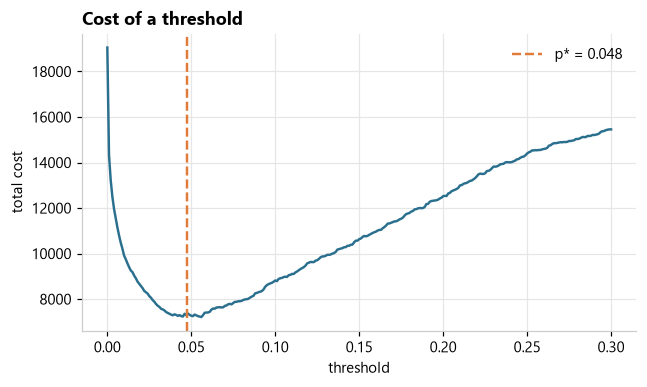

best threshold on the data: 0.056,  formula: 0.048


In [20]:
rng = np.random.default_rng(3)
# calibrated fault probabilities, mean about 5 %
p_true = rng.beta(0.3, 6, 20_000)
y_true = rng.random(20_000) < p_true
C_FP, C_FN = 1.0, 20.0


def total_cost(t):
    false_alarms = np.sum((p_true > t) & ~y_true)
    missed_faults = np.sum((p_true <= t) & y_true)
    return C_FP * false_alarms + C_FN * missed_faults


thr = np.linspace(0, 0.3, 301)
cost = [total_cost(t) for t in thr]
p_star = C_FP / (C_FP + C_FN)

fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.plot(thr, cost, color=BLUE)
ax.axvline(p_star, color=ORANGE, ls="--", label=f"p* = {p_star:.3f}")
ax.set(xlabel="threshold", ylabel="total cost", title="Cost of a threshold")
ax.legend()
plt.show()
best_threshold = thr[int(np.argmin(cost))]
print(f"best threshold on the data: {best_threshold:.3f},  formula: {p_star:.3f}")

The curve is flat near its minimum, so the threshold found on data wanders around $p^*$ from
sample to sample while the cost hardly changes. A threshold far to the right of the dip is the
expensive mistake: every missed fault costs twenty inspections.

## 6.4 How sure is a share? Wald against Wilson

Out of $n = 20$ pumps of one type, $k$ failed. The estimate is $\hat p = k/n$, and the textbook
95 % interval is $\hat p \pm 1.96\sqrt{\hat p(1-\hat p)/n}$ (Wald). At $k = 0$ it collapses to
$[0, 0]$, which claims a certainty that 20 pumps cannot give, and at $k = 1$ its lower end
drops below zero.

The Wilson interval inverts the normal approximation instead of plugging $\hat p$ into it:

$$\frac{k + z^2/2}{n + z^2} \;\pm\; \frac{z}{n + z^2}\sqrt{\frac{k(n-k)}{n} + \frac{z^2}{4}}.$$

Its centre is pulled towards $1/2$ and it never leaves $[0, 1]$. Week 11 ranks failure modes by
its lower bound, so that a mode seen twice in three cycles does not beat one seen 40 times in 100.

In [21]:
def wald(k, n, z=1.96):
    ph = k / n
    half = z * np.sqrt(ph * (1 - ph) / n)
    return ph - half, ph + half


def wilson(k, n, z=1.96):
    centre = (k + z**2 / 2) / (n + z**2)
    half = z / (n + z**2) * np.sqrt(k * (n - k) / n + z**2 / 4)
    return centre - half, centre + half


for k in [0, 1, 10]:
    wald_lo, wald_hi = wald(k, 20)
    wilson_lo, wilson_hi = wilson(k, 20)
    print(f"k = {k:2d} of 20:  Wald [{wald_lo:6.3f}, {wald_hi:.3f}]   "
          f"Wilson [{wilson_lo:.3f}, {wilson_hi:.3f}]")

# how often does each interval contain the true share? It should be 95 %.
rng = np.random.default_rng(4)
p0 = 0.03
n0 = 50
ks = rng.binomial(n0, p0, 100_000)
for name, fn in [("Wald", wald), ("Wilson", wilson)]:
    lo, hi = fn(ks, n0)
    coverage = np.mean((lo <= p0) & (p0 <= hi))
    print(f"{name:6} covers the true p = {p0} in {coverage:.1%} of samples")

k =  0 of 20:  Wald [ 0.000, 0.000]   Wilson [0.000, 0.161]
k =  1 of 20:  Wald [-0.046, 0.146]   Wilson [0.009, 0.236]
k = 10 of 20:  Wald [ 0.281, 0.719]   Wilson [0.299, 0.701]
Wald   covers the true p = 0.03 in 78.1% of samples
Wilson covers the true p = 0.03 in 93.8% of samples


A 95 % interval should contain the true share in 95 % of samples. For a rare event and a small
sample the Wald interval does so far less often, mostly because it collapses to $[0, 0]$
whenever no failure happened to be seen. Wilson stays close to the promised 95 %.

---

# 7. Self-check

Five small functions, each from one section above. Write the body, run the cell, then run the
tests under it. A test that fails says what it expected.

Use NumPy only, no `np.cov`, `np.linalg.lstsq` or ready-made scalers: the point is to write the
formula.

### Task 1. Standardise

`standardize(X)` takes an $n \times d$ array and returns an array of the same shape whose every
column has mean 0 and standard deviation 1 (`np.std` convention, divide by $n$). The input stays
unchanged.

In [ ]:
def standardize(X):
    # your code
    raise NotImplementedError

In [ ]:
def test_columns_have_mean_0_and_std_1():
    rng = np.random.default_rng(10)
    X = rng.normal([5, -3, 100], [1, 4, 20], size=(50, 3))
    Z = standardize(X)
    assert Z.shape == X.shape, f"shape {Z.shape}, expected {X.shape}"
    assert np.allclose(Z.mean(axis=0), 0), "column means are not 0"
    assert np.allclose(Z.std(axis=0), 1), "column stds are not 1 (divide by n)"


test_columns_have_mean_0_and_std_1()


def test_small_case_and_input_untouched():
    X = np.array([[1.0], [2.0], [3.0]])
    Z = standardize(X)
    assert np.allclose(Z.ravel(), [-1.224745, 0, 1.224745]), f"got {np.ravel(Z)}"
    assert np.allclose(X.ravel(), [1, 2, 3]), "the input array was changed"


test_small_case_and_input_untouched()

### Task 2. Covariance by a matrix product

`covariance(X)` returns the $d \times d$ covariance matrix
$\frac{1}{n-1}\mathbf{X}_c^\top\mathbf{X}_c$ of the columns of `X`.

In [ ]:
def covariance(X):
    # your code
    raise NotImplementedError

In [ ]:
def test_matches_the_definition():
    rng = np.random.default_rng(11)
    X = rng.normal(size=(40, 4)) @ rng.normal(size=(4, 4))
    C = covariance(X)
    assert np.shape(C) == (4, 4), f"shape {np.shape(C)}, expected (4, 4)"
    expected = np.cov(X, rowvar=False)
    assert np.allclose(C, expected), "does not match the covariance (divide by n - 1)"


test_matches_the_definition()


def test_symmetric_with_variances_on_the_diagonal():
    X = np.array([[0.0, 1.0], [2.0, 1.0], [4.0, 4.0]])
    C = covariance(X)
    assert np.allclose(C, C.T), "a covariance matrix is symmetric"
    diagonal = np.diag(C)
    assert np.allclose(diagonal, [4.0, 3.0]), f"diagonal {diagonal}, expected [4, 3]"
    assert np.isclose(C[0, 1], 3.0), f"C[0, 1] = {C[0, 1]}, expected 3"


test_symmetric_with_variances_on_the_diagonal()

### Task 3. Least squares and ridge

`least_squares(X, y, lam=0.0)` solves $(\mathbf{X}^\top\mathbf{X} + \lambda\mathbf{I})\mathbf{w} = \mathbf{X}^\top\mathbf{y}$
and returns $\mathbf{w}$, a vector of length $d$. With `lam=0` it is ordinary least squares.

In [ ]:
def least_squares(X, y, lam=0.0):
    # your code
    raise NotImplementedError

In [ ]:
def test_recovers_an_exact_line():
    x = np.arange(10.0)
    X = np.column_stack([np.ones(10), x])
    w = least_squares(X, 2 + 3 * x)
    assert np.shape(w) == (2,), f"shape {np.shape(w)}, expected (2,)"
    assert np.allclose(w, [2, 3]), f"got {w}, expected [2, 3]"


test_recovers_an_exact_line()


def test_residual_is_perpendicular_to_the_columns():
    rng = np.random.default_rng(12)
    X = rng.normal(size=(30, 3))
    y = rng.normal(size=30)
    w = least_squares(X, y)
    assert np.allclose(X.T @ (y - X @ w), 0, atol=1e-9), "X^T (y - Xw) should be zero"


test_residual_is_perpendicular_to_the_columns()


def test_ridge_shrinks_the_weights():
    rng = np.random.default_rng(13)
    X = rng.normal(size=(30, 3))
    y = rng.normal(size=30)
    w0 = least_squares(X, y)
    w1 = least_squares(X, y, lam=5.0)
    expected = np.linalg.solve(X.T @ X + 5 * np.eye(3), X.T @ y)
    assert np.allclose(w1, expected), "with lam the system is (X^T X + lam I) w = X^T y"
    assert np.linalg.norm(w1) < np.linalg.norm(w0), "ridge weights should be smaller"


test_ridge_shrinks_the_weights()

### Task 4. A numerical gradient

`numerical_gradient(f, w, h=1e-5)` returns the vector of central differences
$\big(f(\mathbf{w} + h\mathbf{e}_j) - f(\mathbf{w} - h\mathbf{e}_j)\big)/2h$, one per coordinate
$j$. Here `f` takes a vector and returns a number, and $\mathbf{e}_j$ is the $j$-th unit vector.

In [ ]:
def numerical_gradient(f, w, h=1e-5):
    # your code
    raise NotImplementedError

In [ ]:
def test_gradient_of_a_sum_of_squares():
    w = np.array([1.0, -2.0, 0.5])
    g = numerical_gradient(lambda v: np.sum(v ** 2), w)
    assert np.shape(g) == (3,), f"shape {np.shape(g)}, expected (3,)"
    assert np.allclose(g, 2 * w, atol=1e-6), f"got {g}, expected 2w = {2 * w}"


test_gradient_of_a_sum_of_squares()


def test_gradient_of_least_squares():
    rng = np.random.default_rng(14)
    X = rng.normal(size=(20, 2))
    y = rng.normal(size=20)
    w = rng.normal(size=2)
    g = numerical_gradient(lambda v: np.sum((y - X @ v) ** 2), w)
    expected = -2 * X.T @ (y - X @ w)
    assert np.allclose(g, expected, atol=1e-5), "does not match -2 X^T (y - Xw)"


test_gradient_of_least_squares()

### Task 5. The Wilson interval

`wilson_interval(k, n, z=1.96)` returns the pair `(low, high)` of section 6.4 for $k$ events out
of $n$, clipped to $[0, 1]$.

In [ ]:
def wilson_interval(k, n, z=1.96):
    # your code
    raise NotImplementedError

In [ ]:
def test_known_values():
    lo, hi = wilson_interval(5, 10)
    assert np.isclose(lo, 0.236590, atol=1e-5), f"low end {lo}, expected 0.236590"
    assert np.isclose(hi, 0.763410, atol=1e-5), f"high end {hi}, expected 0.763410"
    lo, hi = wilson_interval(0, 10)
    assert lo == 0 and np.isclose(hi, 0.277540, atol=1e-5), f"for k = 0 got {lo, hi}"


test_known_values()


def test_mirror_and_inside_unit_interval():
    for k in range(0, 13):
        lo, hi = wilson_interval(k, 12)
        lo2, hi2 = wilson_interval(12 - k, 12)
        inside = 0 <= lo <= k / 12 <= hi <= 1
        assert inside, f"k = {k}: the interval must contain k/n and stay in [0, 1]"
        mirrored = np.isclose(lo, 1 - hi2) and np.isclose(hi, 1 - lo2)
        assert mirrored, "k and n - k should mirror"


test_mirror_and_inside_unit_interval()

When a later notebook writes $\mathbf{X}^\top\mathbf{X}$, a gradient, a multiplier or a
quantile and loses you, come back to the section from the table at the top.

For more depth than this notebook gives:

- M. P. Deisenroth, A. A. Faisal, C. S. Ong, *Mathematics for Machine Learning*, Cambridge
  University Press, 2020, free at <https://mml-book.github.io/>: chapters 2–7 cover sections 1–5;
- 3Blue1Brown, *Essence of Linear Algebra*, a video series on what matrices and eigenvectors do
  geometrically.